## How to run in Colab
1. Open [Google Colab](https://colab.research.google.com) → **File → Upload notebook** → choose this file.
2. Download the dataset first: click [Student Mental health.zip](https://github.com/devtlv/Datasets-GEN-AI-Bootcamp/raw/refs/heads/main/Week%203/W3D1%20-%20Data%20Visualization/Student%20Mental%20health.zip). It downloads `Student Mental health.zip`. Save it in `C:\Users\sivan\Datasets`.
3. When the upload cell asks for a file, choose `Student Mental health.zip` from `C:\Users\sivan\Datasets`.

**Run the cells from top to bottom** (Shift+Enter runs one cell). After a restart, run them again from the top.

# Week 2 Day 4 – Exercises XP: Data Visualization

## 👩‍🏫 👩🏿‍🏫 What You’ll learn
- The importance of data visualization in data analysis.
- How to use Matplotlib and Seaborn for creating effective visualizations.
- Choosing the right graph for different data types and purposes.
- Hands-on experience creating and customizing various types of plots.

## Setup
Run this cell first. It imports the libraries used in all the exercises.

In [1]:
import pandas as pd
# pandas: for working with tables (DataFrames)
import matplotlib.pyplot as plt
# matplotlib: for drawing charts
import seaborn as sns
# seaborn: nicer statistical charts, built on top of matplotlib

---
# 🌟 Exercise 1: Understanding Data Visualization
- **Task:** Explain why data visualization is important in data analysis.
- **Task:** Describe the purpose of a line graph in data visualization.

**Why is data visualization important?**
A table full of numbers is hard to read. A chart turns the same numbers into a picture, so we can see patterns, trends and outliers at a glance. It also helps us explain our findings to other people quickly, even if they are not data experts.

**What is a line graph for?**
A line graph shows how a number changes over a continuous range, usually time. The points are joined by lines, so it is easy to see if the values go up, go down, or repeat (for example temperature over a week, or sales over a year).

---
# 🌟 Exercise 2: Creating a Line Plot for Temperature Variation
**Objective:** Line plot of temperatures over a week: `[72, 74, 76, 80, 82, 78, 75]`, x-axis “Day”, y-axis “Temperature (°F)”, a title, then display.

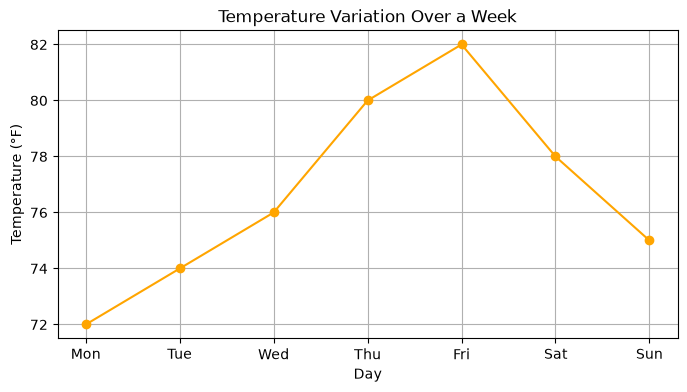

In [2]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
# the 7 days of the week (x values)
temperatures = [72, 74, 76, 80, 82, 78, 75]
# the temperature of each day (y values)
plt.figure(figsize=(8, 4))
# a new chart, 8 wide and 4 high
plt.plot(days, temperatures, marker='o', color='orange')
# draw the line; marker='o' puts a dot on each day
plt.xlabel('Day')
# label of the x axis
plt.ylabel('Temperature (°F)')
# label of the y axis
plt.title('Temperature Variation Over a Week')
# chart title
plt.grid(True)
# light grid lines to read values more easily
plt.show()
# show the chart

---
# 🌟 Exercise 3: Visualizing Monthly Sales with a Bar Chart
**Objective:** Bar chart of monthly sales `[5000, 5500, 6200, 7000, 7500]`, x-axis “Month”, y-axis “Sales Amount ($)”, a title, then display.

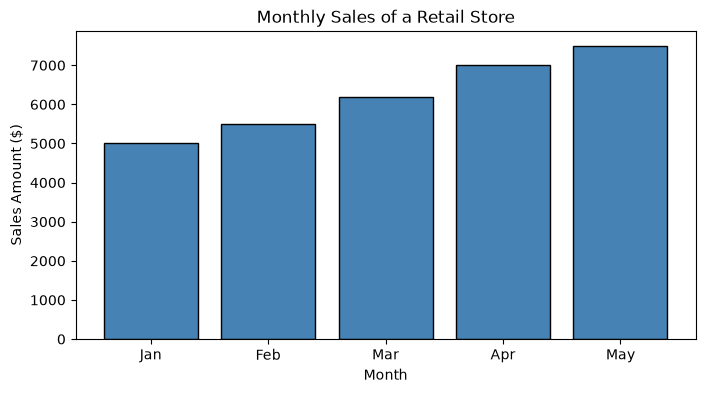

In [3]:
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May']
# 5 months (one per sales value)
sales = [5000, 5500, 6200, 7000, 7500]
# sales of each month
plt.figure(figsize=(8, 4))
# a new chart
plt.bar(months, sales, color='steelblue', edgecolor='black')
# one bar per month; height = sales
plt.xlabel('Month')
# label of the x axis
plt.ylabel('Sales Amount ($)')
# label of the y axis
plt.title('Monthly Sales of a Retail Store')
# chart title
plt.show()
# show the chart

---
## Load the dataset (Exercises 4–6)
Run the upload cell, then read the CSV.

In [ ]:
from google.colab import files
# the Colab tool for uploading files from your computer
uploaded = files.upload()
# choose "Student Mental health.zip" (saved in a variable so its contents are not printed)
!unzip "Student Mental health.zip"
# unzip it: you get the file "Student Mental health.csv"

In [4]:
df = pd.read_csv('Student Mental health.csv')
# read the CSV file into a DataFrame called df
print(df.shape)
# (number of rows, number of columns)
df.head()
# show the first 5 rows

(101, 11)


,Timestamp,Choose your gender,Age,What is your course?,Your current year of Study,What is your CGPA?,Marital status,Do you have Depression?,Do you have Anxiety?,Do you have Panic attack?,Did you seek any specialist for a treatment?
0,8/7/2020 12:02,Female,18.0,Engineering,year 1,3.00 - 3.49,No,Yes,No,Yes,No
1,8/7/2020 12:04,Male,21.0,Islamic education,year 2,3.00 - 3.49,No,No,Yes,No,No
2,8/7/2020 12:05,Male,19.0,BIT,Year 1,3.00 - 3.49,No,Yes,Yes,Yes,No
3,8/7/2020 12:06,Female,22.0,Laws,year 3,3.00 - 3.49,Yes,Yes,No,No,No
4,8/7/2020 12:13,Male,23.0,Mathemathics,year 4,3.00 - 3.49,No,No,No,No,No


In [5]:
print(df.columns.tolist())
# list of all column names, so we spell them correctly
print(df['What is your CGPA?'].unique())
# the different CGPA ranges in the data

['Timestamp', 'Choose your gender', 'Age', 'What is your course?', 'Your current year of Study', 'What is your CGPA?', 'Marital status', 'Do you have Depression?', 'Do you have Anxiety?', 'Do you have Panic attack?', 'Did you seek any specialist for a treatment?']
<StringArray>
[ '3.00 - 3.49',  '3.50 - 4.00', '3.50 - 4.00 ',  '2.50 - 2.99',
  '2.00 - 2.49',     '0 - 1.99']
Length: 6, dtype: str


Some CGPA values have an extra space at the end (`'3.50 - 4.00 '`), so the same range would be counted twice. We remove the spaces with `.str.strip()`.

In [6]:
df['What is your CGPA?'] = df['What is your CGPA?'].str.strip()
# remove spaces at the start/end of each CGPA text
print(df['What is your CGPA?'].value_counts())
# how many students are in each CGPA range

What is your CGPA?
3.50 - 4.00    48
3.00 - 3.49    43
2.50 - 2.99     4
0 - 1.99        4
2.00 - 2.49     2
Name: count, dtype: int64


---
# 🌟 Exercise 4: Visualizing the Distribution of CGPA
**Objective:** Histogram of the CGPA categories with Seaborn’s `histplot`, a specific color and a title.

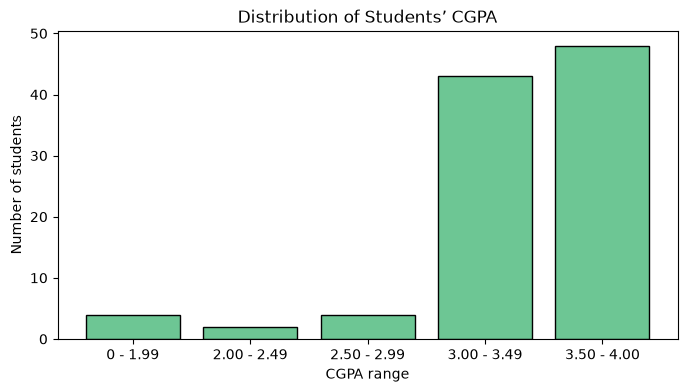

In [7]:
cgpa_order = ['0 - 1.99', '2.00 - 2.49', '2.50 - 2.99', '3.00 - 3.49', '3.50 - 4.00']
# the ranges from lowest to highest, so the bars are in a logical order
df['CGPA'] = pd.Categorical(df['What is your CGPA?'], categories=cgpa_order, ordered=True)
# a new column with the same values, but pandas now knows their order
plt.figure(figsize=(8, 4))
# a new chart
sns.histplot(data=df, x='CGPA', color='mediumseagreen', shrink=0.8)
# count students in each CGPA range; shrink=0.8 leaves a gap between bars
plt.title('Distribution of Students’ CGPA')
# chart title
plt.xlabel('CGPA range')
# label of the x axis
plt.ylabel('Number of students')
# label of the y axis
plt.show()
# show the chart

**What we see:** most students have a CGPA between 3.00 and 4.00; very few are below 3.00.

---
# 🌟 Exercise 5: Comparing Anxiety Levels Across Different Genders
**Objective:** Bar plot of the proportion of students with anxiety (‘Do you have Anxiety?’) for each gender (‘Choose your gender’), with a color palette and a title.

In [8]:
df['Anxiety'] = df['Do you have Anxiety?'].map({'Yes': 1, 'No': 0})
# turn Yes/No into 1/0, so the average of the column = proportion of 'Yes'
print(df.groupby('Choose your gender')['Anxiety'].mean())
# proportion of students with anxiety for each gender

Choose your gender
Female    0.320000
Male      0.384615
Name: Anxiety, dtype: float64


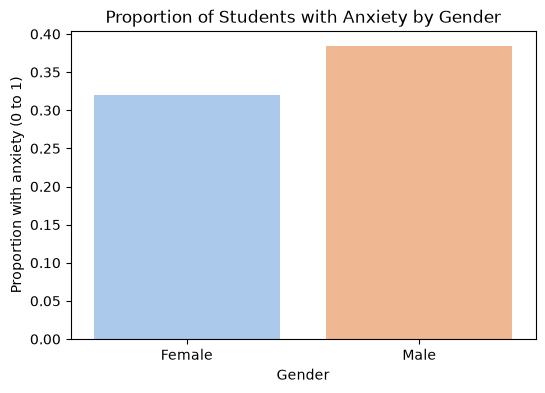

In [9]:
plt.figure(figsize=(6, 4))
# a new chart
sns.barplot(data=df, x='Choose your gender', y='Anxiety', hue='Choose your gender', palette='pastel', errorbar=None, legend=False)
# barplot shows the AVERAGE of y for each x = proportion with anxiety
plt.title('Proportion of Students with Anxiety by Gender')
# chart title
plt.xlabel('Gender')
# label of the x axis
plt.ylabel('Proportion with anxiety (0 to 1)')
# label of the y axis
plt.show()
# show the chart

**What we see:** the proportion of students with anxiety is about the same for women and men (around one third).

---
# 🌟 Exercise 6: Exploring the Relationship Between Age and Panic Attacks
**Objective:** Scatter plot of ‘Age’ vs. panic attacks converted to numbers (Yes=1, No=0), with labels, a title and styled points.

Note: in this file the column is called **‘Do you have Panic attack?’**.

In [10]:
df['Panic'] = df['Do you have Panic attack?'].map({'Yes': 1, 'No': 0})
# Yes -> 1, No -> 0
df_age = df.dropna(subset=['Age'])
# one student has no age, so we leave that row out
print(df_age[['Age', 'Panic']].head())
# check the new numbers

    Age  Panic
0  18.0      1
1  21.0      0
2  19.0      1
3  22.0      0
4  23.0      0


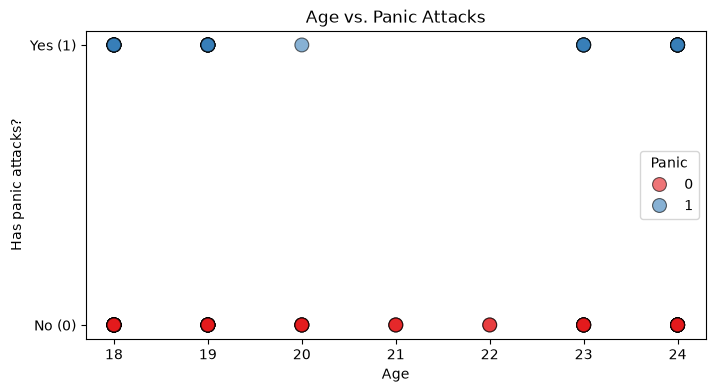

In [11]:
plt.figure(figsize=(8, 4))
# a new chart
sns.scatterplot(data=df_age, x='Age', y='Panic', hue='Panic', palette='Set1', s=100, alpha=0.6, marker='o', edgecolor='black')
# one dot per student; s = dot size, alpha = transparency (overlapping dots look darker)
plt.yticks([0, 1], ['No (0)', 'Yes (1)'])
# show words instead of only 0 and 1 on the y axis
plt.title('Age vs. Panic Attacks')
# chart title
plt.xlabel('Age')
# label of the x axis
plt.ylabel('Has panic attacks?')
# label of the y axis
plt.show()
# show the chart

**What we see:** students of every age (18–24) appear in both rows, so there is no clear link between age and panic attacks in this small dataset.